# Korak 2(a): liha barvanja ravninskih grafov brez sosednjih trikotnikov

Za vsak red `n` generira povezane neizomorfne grafe z `geng`, obdrži ravninske grafe z `planarg`, izloči grafe z dvema trikotnikoma, ki imata skupno povezavo, in izračuna `χ_o(G)` z `odd_coloring.py`. Rezultate po vsakem redu shrani v `rezultati_a.json`.

In [1]:
from pathlib import Path
import sys
import shutil
import subprocess
import json
import time
from itertools import combinations

# Če notebook ni shranjen v korenu repozitorija, tukaj nastavi pot do lokalnega klona.
REPO_DIR = Path.cwd()
if not (REPO_DIR / 'odd_coloring.py').exists():
    raise FileNotFoundError(
        'V trenutni mapi ni odd_coloring.py. Shrani notebook v koren lokalnega klona '
        'OR-projekt ali nastavi REPO_DIR na mapo klona.'
    )
sys.path.insert(0, str(REPO_DIR))
from odd_coloring import G_to_adj, odd_chromatic_number, is_odd_coloring

GENG = shutil.which('geng')
PLANARG = shutil.which('planarg')
print('Repozitorij:', REPO_DIR)
print('geng:', GENG)
print('planarg:', PLANARG)
if not GENG or not PLANARG:
    raise RuntimeError(
        'Ukaza geng in/ali planarg nista v PATH. Zaženi VS Code iz SageMath okolja '
        'oziroma uporabi SageMath kernel, v katerem sta na voljo nauty programa.'
    )

Repozitorij: /mnt/c/Users/kozel/OneDrive/Dokumenti/4. Letnik faks/Finančni Praktikum/Projekt
geng: /home/kozel/miniforge3/envs/sage/bin/geng
planarg: /home/kozel/miniforge3/envs/sage/bin/planarg


## Filter za sosednja 3-cikla

Dva trikotnika sta sosednja, če si delita povezavo. Pregledamo vse trojice vozlišč in za vsak trikotnik povečamo število trikotnikov, ki vsebujejo posamezno povezavo. Če katera povezava pripada več kot enemu trikotniku, graf ne spada v razred (a). To preverja tudi trikotnike s tetivami, ne samo lica ravninske vložitve.

In [2]:
def has_adjacent_triangles(G):
    vertices = list(G.vertices())
    triangles_per_edge = {}

    for a, b, c in combinations(vertices, 3):
        if G.has_edge(a, b) and G.has_edge(a, c) and G.has_edge(b, c):
            for edge in ((a, b), (a, c), (b, c)):
                key = frozenset(edge)
                triangles_per_edge[key] = triangles_per_edge.get(key, 0) + 1
                if triangles_per_edge[key] > 1:
                    return True
    return False

# Majhni kontrolni primeri za filter.
K3 = graphs.CompleteGraph(3)
assert not has_adjacent_triangles(K3)
diamond = Graph([(0, 1), (0, 2), (1, 2), (0, 3), (1, 3)])  # trikotnika delita 0--1
assert has_adjacent_triangles(diamond)
bow_tie = Graph([(0, 1), (1, 2), (2, 0), (0, 3), (3, 4), (4, 0)])  # skupno le vozlišče 0
assert not has_adjacent_triangles(bow_tie)
assert not has_adjacent_triangles(graphs.PathGraph(6))
print('Kontrolni testi filtra trikotnikov: OK')

Kontrolni testi filtra trikotnikov: OK


## Preizkus generatorjev

Pri treh vozliščih sta natanko dva povezana neizomorfna ravninska grafa: pot `P3` in trikotnik `K3`. Ta kratek preizkus preveri cev `geng | planarg` in branje formata graph6, preden začnemo daljši izračun.

In [3]:
def geng_planarg_graphs(n):
    # Povezan graf reda n ima vsaj n-1 povezav. Ravninski enostavni graf
    # ima največ 3n-6 povezav za n >= 3; pri n=1,2 uporabimo popoln bound.
    min_edges = n - 1
    max_edges = n * (n - 1) // 2 if n < 3 else 3 * n - 6
    edge_range = f'{min_edges}:{max_edges}'

    geng = subprocess.Popen(
        [GENG, '-q', '-c', str(n), edge_range],
        stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True
    )
    planarg = subprocess.Popen(
        [PLANARG, '-q'],
        stdin=geng.stdout, stdout=subprocess.PIPE, stderr=subprocess.PIPE, text=True
    )
    geng.stdout.close()  # dovolimo geng-u, da zazna, če se planarg konča

    for line in planarg.stdout:
        code = line.strip()
        if code:
            yield Graph(code, format='graph6')

    planarg.stdout.close()
    planarg_stderr = planarg.stderr.read()
    geng_stderr = geng.stderr.read()
    planarg.stderr.close()
    geng.stderr.close()
    planarg_rc = planarg.wait()
    geng_rc = geng.wait()
    if planarg_rc != 0 or geng_rc != 0:
        raise RuntimeError(
            f'geng/planarg se ni uspešno zaključil: geng={geng_rc}, planarg={planarg_rc}\n'
            f'geng stderr: {geng_stderr}\nplanarg stderr: {planarg_stderr}'
        )

small_planar = list(geng_planarg_graphs(3))
assert len(small_planar) == 2, f'Pričakovana sta 2 grafa, dobil sem {len(small_planar)}'
assert all(G.is_planar() for G in small_planar)
print('Preizkus geng | planarg: OK; grafov reda 3:', len(small_planar))

Preizkus geng | planarg: OK; grafov reda 3: 2


## Pregled enega reda in shranjevanje rezultatov

Za vsak generiran ravninski graf najprej uporabimo filter razreda (a), nato natančen algoritem `odd_chromatic_number`. Shranimo število grafov, porazdelitev po vrednosti `χ_o`, največjo vrednost, graph6 zapise vseh grafov z `χ_o=5` in tudi morebitne primere z več kot 5 barvami. Generator `geng` vrne po enega predstavnika vsakega neizomorfnega grafa, zato se ista abstraktna struktura ne šteje večkrat zaradi različnih ravninskih vložitev.

In [4]:
def analyze_order(n, progress_every=10000):
    n = int(n)  # Sage Integer pretvorimo v Python int za JSON
    start = time.time()
    planar_count = 0
    class_count = 0
    histogram = {}
    max_chi = 0
    graphs_chi_5 = []
    graphs_chi_above_5 = []

    for G in geng_planarg_graphs(n):
        planar_count += 1
        if has_adjacent_triangles(G):
            continue
        class_count += 1

        adj = G_to_adj(G)
        chi, coloring = odd_chromatic_number(adj)
        assert is_odd_coloring(adj, coloring)

        chi = int(chi)
        histogram[str(chi)] = histogram.get(str(chi), 0) + 1
        max_chi = max(max_chi, chi)
        code = G.graph6_string().strip()
        if chi == 5:
            graphs_chi_5.append(code)
        elif chi > 5:
            graphs_chi_above_5.append({'chi': chi, 'graph6': code})

        if progress_every and planar_count % progress_every == 0:
            elapsed = time.time() - start
            print(f'n={n}: pregledanih ravninskih {planar_count:,}; '
                  f'razred (a) {class_count:,}; {elapsed:.1f} s')

    return {
        'n': int(n),
        'planar_connected_graphs': int(planar_count),
        'graphs_in_class_a': int(class_count),
        'chi_histogram': {key: int(value) for key, value in histogram.items()},
        'max_chi': int(max_chi),
        'graphs_chi_5_graph6': graphs_chi_5,
        'graphs_chi_above_5': graphs_chi_above_5,
        'seconds': float(round(time.time() - start, 2)),
    }

def _json_default(value):
    # SageMath razširi tudi števce in literale v Sage Integer.
    if isinstance(value, Integer):
        return int(value)
    if (type(value).__module__.startswith('sage.') or
            type(value).__name__.startswith('Real')) and hasattr(value, '__float__'):
        return float(value)
    raise TypeError(f'{type(value).__name__} ni JSON-zapisljiv')

def save_checkpoint(results, filename='rezultati_a.json'):
    path = REPO_DIR / filename
    temporary_path = path.with_suffix('.json.tmp')
    temporary_path.write_text(
        json.dumps(results, ensure_ascii=False, indent=int(2), default=_json_default),
        encoding='utf-8'
    )
    temporary_path.replace(path)
    return path

# Preverimo ravno serializacijo tipov, ki jih SageMath uporablja v rezultatih.
_json_smoke = json.loads(json.dumps(
    {'sage_integer': Integer(1), 'sage_real': RDF(0.25)},
    default=_json_default
))
assert _json_smoke == {'sage_integer': 1, 'sage_real': 0.25}
print('Sage → JSON pretvorba: OK')

def run_orders(n_start=1, n_end=10, filename='rezultati_a.json'):
    path = REPO_DIR / filename
    if path.exists():
        results = json.loads(path.read_text(encoding='utf-8'))
        print('Nadaljujem iz obstoječih rezultatov:', path)
    else:
        results = {}

    for n in range(n_start, n_end + 1):
        n = int(n)  # Sage range lahko vrača Sage Integer
        key = str(n)
        if key in results:
            print(f'n={n}: že shranjeno, preskočim')
            continue
        print(f'Začenjam red n={n}')
        results[key] = analyze_order(n)
        saved_to = save_checkpoint(results, filename)
        row = results[key]
        print(f"n={n}: razred (a) {row['graphs_in_class_a']:,}; "
              f"max χ_o={row['max_chi']}; χ_o=5: "
              f"{len(row['graphs_chi_5_graph6'])}; shranjeno v {saved_to}")
    return results

Sage → JSON pretvorba: OK


# Korak 2(b): brez dveh sosednjih kratkih ciklov

Obravnavamo dva razreda ločeno: `L=4` pomeni brez dveh sosednjih ciklov dolžine največ 4, `L=5` pa brez dveh sosednjih ciklov dolžine največ 5. Cikla sta sosednja, če imata skupno povezavo. Spodnji DFS poišče vse enostavne cikle do zahtevane dolžine; s tem zajame tudi cikle s tetivami, ne le lica vložitve. Rezultati se shranjujejo ločeno v `rezultati_b4.json` in `rezultati_b5.json`.

In [5]:
def short_cycle_edge_sets(G, max_length):
    # Vozlišča preštevilčimo v 0..n-1, da je vrstni red vedno primerljiv.
    vertices = list(G.vertices())
    index = {v: i for i, v in enumerate(vertices)}
    adjacency = [
        {index[u] for u in G.neighbors(v)}
        for v in vertices
    ]
    cycle_edges = []

    for start in range(len(vertices)):
        def extend(path):
            last = path[-1]

            # Zapremo cikel. start je najmanjše vozlišče cikla;
            # path[1] < last izbere samo eno od dveh smeri.
            if len(path) >= 3 and start in adjacency[last] and path[1] < last:
                edges = frozenset(
                    frozenset((path[i], path[(i + 1) % len(path)]))
                    for i in range(len(path))
                )
                cycle_edges.append(edges)

            if len(path) == max_length:
                return

            for nxt in adjacency[last]:
                if nxt > start and nxt not in path:
                    extend(path + [nxt])

        for nxt in adjacency[start]:
            if nxt > start:
                extend([start, nxt])

    return cycle_edges

def has_adjacent_cycles_at_most(G, max_length):
    used_edges = set()
    for edges in short_cycle_edge_sets(G, max_length):
        if used_edges.intersection(edges):
            return True
        used_edges.update(edges)
    return False

# Filter tests: one triangle passes; shared-edge triangles fail;
# triangles sharing only one vertex pass; two pentagons sharing one edge
# are allowed for L=4 but forbidden for L=5.
assert not has_adjacent_cycles_at_most(graphs.CompleteGraph(3), 4)
assert has_adjacent_cycles_at_most(diamond, 4)
assert not has_adjacent_cycles_at_most(bow_tie, 5)
two_pentagons_one_edge = Graph([
    (0, 1), (1, 2), (2, 3), (3, 4), (4, 0),
    (1, 5), (5, 6), (6, 7), (7, 0)
])
assert not has_adjacent_cycles_at_most(two_pentagons_one_edge, 4)
assert has_adjacent_cycles_at_most(two_pentagons_one_edge, 5)
assert len(short_cycle_edge_sets(two_pentagons_one_edge, 5)) == 2
print('Kontrolni testi filtrov za 2(b): OK')

Kontrolni testi filtrov za 2(b): OK


In [6]:
def analyze_order_b(n, max_cycle_length, progress_every=10000):
    n = int(n)
    start_time = time.time()
    planar_count = 0
    class_count = 0
    histogram = {}
    max_chi = 0
    graphs_chi_5 = []
    graphs_chi_above_5 = []

    for G in geng_planarg_graphs(n):
        planar_count += 1
        if has_adjacent_cycles_at_most(G, max_cycle_length):
            continue
        class_count += 1

        adj = G_to_adj(G)
        chi, coloring = odd_chromatic_number(adj)
        chi = int(chi)
        assert is_odd_coloring(adj, coloring)
        histogram[str(chi)] = histogram.get(str(chi), 0) + 1
        max_chi = max(max_chi, chi)
        code = G.graph6_string().strip()
        if chi == 5:
            graphs_chi_5.append(code)
        elif chi > 5:
            graphs_chi_above_5.append({'chi': chi, 'graph6': code})

        if progress_every and planar_count % progress_every == 0:
            print(f'L={max_cycle_length}, n={n}: pregledanih {planar_count:,}; '
                  f'v razredu {class_count:,}; {time.time() - start_time:.1f} s')

    return {
        'n': int(n),
        'max_cycle_length': int(max_cycle_length),
        'planar_connected_graphs': int(planar_count),
        'graphs_in_class': int(class_count),
        'chi_histogram': {key: int(value) for key, value in histogram.items()},
        'max_chi': int(max_chi),
        'graphs_chi_5_graph6': graphs_chi_5,
        'graphs_chi_above_5': graphs_chi_above_5,
        'seconds': float(time.time() - start_time),
    }

def run_orders_b(max_cycle_length, n_start=1, n_end=10, progress_every=10000):
    if max_cycle_length not in (4, 5):
        raise ValueError('max_cycle_length mora biti 4 ali 5')
    filename = f'rezultati_b{max_cycle_length}.json'
    path = REPO_DIR / filename
    results = json.loads(path.read_text(encoding='utf-8')) if path.exists() else {}

    for n in range(n_start, n_end + 1):
        n = int(n)
        key = str(n)
        if key in results:
            print(f'L={max_cycle_length}, n={n}: že shranjeno, preskočim')
            continue
        print(f'Začenjam L={max_cycle_length}, n={n}')
        results[key] = analyze_order_b(n, max_cycle_length, progress_every)
        save_checkpoint(results, filename)
        row = results[key]
        print(f"n={n}: grafov v razredu {row['graphs_in_class']:,}; "
              f"max χ_o={row['max_chi']}; χ_o=5: "
              f"{len(row['graphs_chi_5_graph6'])}; nad 5: "
              f"{len(row['graphs_chi_above_5'])}")
    return results

# Koraki 2(c), 2(d) in 2(e)

(c) prepove vsak par kratkih ciklov dolžine največ 4, ki ima skupno vozlišče. (d) prepove graf, v katerem obstaja 4-cikel, ki ima skupno povezavo z vsaj dvema različnima 4-cikloma. (e) prepove vsak par ciklov dolžine največ 5 s skupnim vozliščem. Vsi cikli so enostavni cikli grafa, vključno s cikli s tetivami. Vsak razred analiziramo posebej z istim natančnim algoritmom za liho kromatično število.

In [7]:
def has_intersecting_cycles_at_most(G, max_length):
    # Dva cikla se sekata, če imata vsaj eno skupno vozlišče.
    seen_vertices = set()
    for edges in short_cycle_edge_sets(G, max_length):
        cycle_vertices = {v for edge in edges for v in edge}
        if seen_vertices.intersection(cycle_vertices):
            return True
        seen_vertices.update(cycle_vertices)
    return False

def has_four_cycle_adjacent_to_two_four_cycles(G):
    # Za vsak 4-cikel zberemo vse druge 4-cikle, s katerimi deli povezavo.
    four_cycles = [
        edges for edges in short_cycle_edge_sets(G, 4) if len(edges) == 4
    ]
    adjacent = [set() for _ in four_cycles]
    cycles_by_edge = {}
    for i, edges in enumerate(four_cycles):
        for edge in edges:
            cycles_by_edge.setdefault(edge, []).append(i)
    for cycle_ids in cycles_by_edge.values():
        for i in cycle_ids:
            adjacent[i].update(j for j in cycle_ids if j != i)
    return any(len(neighbors) >= 2 for neighbors in adjacent)

# Kontrolni grafi za (c), (d) in (e).
assert not has_intersecting_cycles_at_most(K3, 4)
assert has_intersecting_cycles_at_most(bow_tie, 4)  # skupno vozlišče
assert not has_intersecting_cycles_at_most(two_pentagons_one_edge, 4)
assert has_intersecting_cycles_at_most(two_pentagons_one_edge, 5)
square = Graph([(0, 1), (1, 2), (2, 3), (3, 0)])
assert not has_four_cycle_adjacent_to_two_four_cycles(square)
two_squares_share_edge = Graph([
    (0, 1), (1, 2), (2, 3), (3, 0),
    (1, 4), (4, 5), (5, 0)
])
assert not has_four_cycle_adjacent_to_two_four_cycles(two_squares_share_edge)
three_squares = Graph([
    (0, 1), (1, 2), (2, 3), (3, 0),
    (1, 4), (4, 5), (5, 0),
    (3, 6), (6, 7), (7, 2)
])
assert has_four_cycle_adjacent_to_two_four_cycles(three_squares)
print('Kontrolni testi za 2(c), 2(d), 2(e): OK')

Kontrolni testi za 2(c), 2(d), 2(e): OK


In [8]:
def analyze_order_named(n, class_key, belongs_to_class, progress_every=10000):
    n = int(n)
    start_time = time.time()
    planar_count = 0
    class_count = 0
    histogram = {}
    max_chi = 0
    graphs_chi_5 = []
    graphs_chi_above_5 = []

    for G in geng_planarg_graphs(n):
        planar_count += 1
        if not belongs_to_class(G):
            continue
        class_count += 1
        adj = G_to_adj(G)
        chi, coloring = odd_chromatic_number(adj)
        chi = int(chi)
        assert is_odd_coloring(adj, coloring)
        histogram[str(chi)] = histogram.get(str(chi), 0) + 1
        max_chi = max(max_chi, chi)
        code = G.graph6_string().strip()
        if chi == 5:
            graphs_chi_5.append(code)
        elif chi > 5:
            graphs_chi_above_5.append({'chi': chi, 'graph6': code})

        if progress_every and planar_count % progress_every == 0:
            print(f'{class_key}, n={n}: planarnih {planar_count:,}; '
                  f'v razredu {class_count:,}; {time.time() - start_time:.1f} s')

    return {
        'class': class_key,
        'n': int(n),
        'planar_connected_graphs': int(planar_count),
        'graphs_in_class': int(class_count),
        'chi_histogram': {key: int(value) for key, value in histogram.items()},
        'max_chi': int(max_chi),
        'graphs_chi_5_graph6': graphs_chi_5,
        'graphs_chi_above_5': graphs_chi_above_5,
        'seconds': float(time.time() - start_time),
    }

def run_class_orders(class_key, belongs_to_class, n_start=1, n_end=10, progress_every=10000):
    filename = f'rezultati_{class_key}.json'
    path = REPO_DIR / filename
    results = json.loads(path.read_text(encoding='utf-8')) if path.exists() else {}
    for n in range(n_start, n_end + 1):
        n = int(n)
        key = str(n)
        if key in results:
            print(f'{class_key}, n={n}: že shranjeno, preskočim')
            continue
        print(f'Začenjam razred {class_key}, n={n}')
        results[key] = analyze_order_named(
            n, class_key, belongs_to_class, progress_every=progress_every
        )
        save_checkpoint(results, filename)
        row = results[key]
        print(f"{class_key}, n={n}: grafov v razredu {row['graphs_in_class']:,}; "
              f"max χ_o={row['max_chi']}; χ_o=5: "
              f"{len(row['graphs_chi_5_graph6'])}; nad 5: "
              f"{len(row['graphs_chi_above_5'])}")
    return results

In [9]:
# Ko preveriš hitrost in rezultate, nadaljuj do n=10.
# Že zaključene rede bo prebralo iz rezultati_a.json in jih preskočilo.
results = run_orders(n_start=1, n_end=10)

Nadaljujem iz obstoječih rezultatov: /mnt/c/Users/kozel/OneDrive/Dokumenti/4. Letnik faks/Finančni Praktikum/Projekt/rezultati_a.json
n=1: že shranjeno, preskočim
n=2: že shranjeno, preskočim
n=3: že shranjeno, preskočim
n=4: že shranjeno, preskočim
n=5: že shranjeno, preskočim
n=6: že shranjeno, preskočim
n=7: že shranjeno, preskočim
n=8: že shranjeno, preskočim
n=9: že shranjeno, preskočim
n=10: že shranjeno, preskočim


In [10]:
# Celoten izračun za L=4 (že shranjeni redi se preskočijo).
results_b4 = run_orders_b(max_cycle_length=4, n_start=1, n_end=10)

L=4, n=1: že shranjeno, preskočim
L=4, n=2: že shranjeno, preskočim
L=4, n=3: že shranjeno, preskočim
L=4, n=4: že shranjeno, preskočim
L=4, n=5: že shranjeno, preskočim
L=4, n=6: že shranjeno, preskočim
L=4, n=7: že shranjeno, preskočim
L=4, n=8: že shranjeno, preskočim
L=4, n=9: že shranjeno, preskočim
L=4, n=10: že shranjeno, preskočim


In [11]:
# Celoten izračun za L=5.
results_b5 = run_orders_b(max_cycle_length=5, n_start=1, n_end=10)

L=5, n=1: že shranjeno, preskočim
L=5, n=2: že shranjeno, preskočim
L=5, n=3: že shranjeno, preskočim
L=5, n=4: že shranjeno, preskočim
L=5, n=5: že shranjeno, preskočim
L=5, n=6: že shranjeno, preskočim
L=5, n=7: že shranjeno, preskočim
L=5, n=8: že shranjeno, preskočim
L=5, n=9: že shranjeno, preskočim
L=5, n=10: že shranjeno, preskočim


In [12]:
N_MAX = 10

class_c = lambda G: not has_intersecting_cycles_at_most(G, 4)
class_d = lambda G: not has_four_cycle_adjacent_to_two_four_cycles(G)
class_e = lambda G: not has_intersecting_cycles_at_most(G, 5)

results_c = run_class_orders('c', class_c, n_end=N_MAX)
results_d = run_class_orders('d', class_d, n_end=N_MAX)
results_e = run_class_orders('e', class_e, n_end=N_MAX)

Začenjam razred c, n=1
c, n=1: grafov v razredu 1; max χ_o=1; χ_o=5: 0; nad 5: 0
Začenjam razred c, n=2
c, n=2: grafov v razredu 1; max χ_o=2; χ_o=5: 0; nad 5: 0
Začenjam razred c, n=3
c, n=3: grafov v razredu 2; max χ_o=3; χ_o=5: 0; nad 5: 0
Začenjam razred c, n=4
c, n=4: grafov v razredu 4; max χ_o=4; χ_o=5: 0; nad 5: 0
Začenjam razred c, n=5
c, n=5: grafov v razredu 8; max χ_o=5; χ_o=5: 1; nad 5: 0
Začenjam razred c, n=6
c, n=6: grafov v razredu 22; max χ_o=4; χ_o=5: 0; nad 5: 0
Začenjam razred c, n=7
c, n=7: grafov v razredu 63; max χ_o=4; χ_o=5: 0; nad 5: 0
Začenjam razred c, n=8
c, n=8: grafov v razredu 224; max χ_o=4; χ_o=5: 0; nad 5: 0
Začenjam razred c, n=9
c, n=9: grafov v razredu 896; max χ_o=5; χ_o=5: 2; nad 5: 0
Začenjam razred c, n=10
c, n=10: planarnih 10,000; v razredu 718; 1.3 s
c, n=10: grafov v razredu 4,230; max χ_o=4; χ_o=5: 0; nad 5: 0
Začenjam razred d, n=1
d, n=1: grafov v razredu 1; max χ_o=1; χ_o=5: 0; nad 5: 0
Začenjam razred d, n=2
d, n=2: grafov v razredu 1

## Pregled povzetka

V `rezultati_a.json` so shranjene tudi vse graph6 kode grafov z `χ_o=5`. Kodo lahko pretvoriš v Sage graf in ga izrišeš. Za poročilo ohranimo tudi število pregledanih grafov in čas računanja za vsak red.

In [13]:
summary = []
for n, row in sorted(results.items(), key=lambda item: int(item[0])):
    summary.append({
        'n': int(n),
        'graphs_in_class_a': row['graphs_in_class_a'],
        'max_chi': row['max_chi'],
        'number_with_chi_5': len(row['graphs_chi_5_graph6']),
        'number_above_5': len(row['graphs_chi_above_5']),
        'seconds': row['seconds'],
    })
summary

[{'n': 1,
  'graphs_in_class_a': 1,
  'max_chi': 1,
  'number_with_chi_5': 0,
  'number_above_5': 0,
  'seconds': 0.0},
 {'n': 2,
  'graphs_in_class_a': 1,
  'max_chi': 2,
  'number_with_chi_5': 0,
  'number_above_5': 0,
  'seconds': 0.0},
 {'n': 3,
  'graphs_in_class_a': 2,
  'max_chi': 3,
  'number_with_chi_5': 0,
  'number_above_5': 0,
  'seconds': 0.0},
 {'n': 4,
  'graphs_in_class_a': 4,
  'max_chi': 4,
  'number_with_chi_5': 0,
  'number_above_5': 0,
  'seconds': 0.0},
 {'n': 5,
  'graphs_in_class_a': 11,
  'max_chi': 5,
  'number_with_chi_5': 1,
  'number_above_5': 0,
  'seconds': 0.01},
 {'n': 6,
  'graphs_in_class_a': 38,
  'max_chi': 4,
  'number_with_chi_5': 0,
  'number_above_5': 0,
  'seconds': 0.01},
 {'n': 7,
  'graphs_in_class_a': 159,
  'max_chi': 5,
  'number_with_chi_5': 1,
  'number_above_5': 0,
  'seconds': 0.05},
 {'n': 8,
  'graphs_in_class_a': 882,
  'max_chi': 5,
  'number_with_chi_5': 2,
  'number_above_5': 0,
  'seconds': 0.3},
 {'n': 9,
  'graphs_in_class_a'

n = 8 |m| = 10 | χ_o = 5


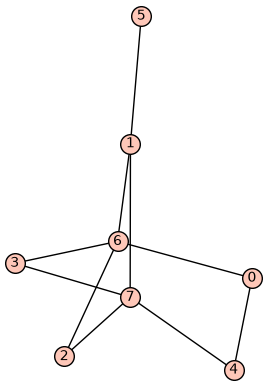

n = 8 |m| = 11 | χ_o = 5


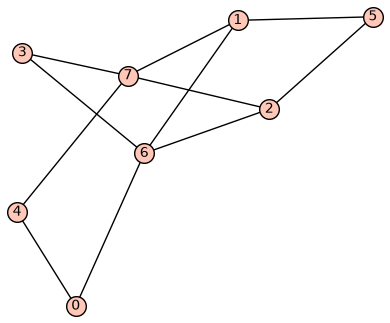

In [25]:
# Izriši vse najdene grafe z χ_o=5 pri izbranem redu.
n = 8 # spremeni po potrebi
codes = results[str(n)]['graphs_chi_5_graph6']
for code in codes:
    G = Graph(code, format='graph6')
    print('n =', G.order(), '|m| =', G.size(), '| χ_o =', odd_chromatic_number(G_to_adj(G))[0])
    G.show()

## Povzetek in ogled 5-barvnih primerov

Za tabelo povzetka naložimo checkpoint JSON. Graph6 kodo pretvorimo nazaj v Sage graf za pregled in izris.

In [15]:
def summary_b(results):
    return [
        {
            'n': int(n),
            'graphs_in_class': row['graphs_in_class'],
            'max_chi': row['max_chi'],
            'number_with_chi_5': len(row['graphs_chi_5_graph6']),
            'number_above_5': len(row['graphs_chi_above_5']),
            'seconds': row['seconds'],
        }
        for n, row in sorted(results.items(), key=lambda item: int(item[0]))
    ]

summary_b4 = summary_b(results_b4)
summary_b5 = summary_b(results_b5)
summary_b4, summary_b5

([{'n': 1,
   'graphs_in_class': 1,
   'max_chi': 1,
   'number_with_chi_5': 0,
   'number_above_5': 0,
   'seconds': 0.003335237503051758},
  {'n': 2,
   'graphs_in_class': 1,
   'max_chi': 2,
   'number_with_chi_5': 0,
   'number_above_5': 0,
   'seconds': 0.002392292022705078},
  {'n': 3,
   'graphs_in_class': 2,
   'max_chi': 3,
   'number_with_chi_5': 0,
   'number_above_5': 0,
   'seconds': 0.0025358200073242188},
  {'n': 4,
   'graphs_in_class': 4,
   'max_chi': 4,
   'number_with_chi_5': 0,
   'number_above_5': 0,
   'seconds': 0.003239154815673828},
  {'n': 5,
   'graphs_in_class': 9,
   'max_chi': 5,
   'number_with_chi_5': 1,
   'number_above_5': 0,
   'seconds': 0.005233049392700195},
  {'n': 6,
   'graphs_in_class': 25,
   'max_chi': 4,
   'number_with_chi_5': 0,
   'number_above_5': 0,
   'seconds': 0.014206409454345703},
  {'n': 7,
   'graphs_in_class': 80,
   'max_chi': 4,
   'number_with_chi_5': 0,
   'number_above_5': 0,
   'seconds': 0.07548189163208008},
  {'n': 8,


In [16]:
# Izriši 5-barvne grafe iz izbranega checkpointa.
L = 4  # nastavi na 5 za drugi razred
n = 6  # izbrani red
filename = f'rezultati_b{L}.json'
saved = json.loads((REPO_DIR / filename).read_text(encoding='utf-8'))
for code in saved[str(n)]['graphs_chi_5_graph6']:
    G = Graph(code, format='graph6')
    print(f'n={n}, m={G.size()}, L={L}')
    G.show()

## Skupni pregled rezultatov (a)–(e)

Ta pregled prebere shranjene checkpoint datoteke za vse pet razredov. `max_chi` je največja najdena vrednost za dani red; `graphs_chi_5_graph6` vsebuje zapise vseh neizomorfnih grafov v razredu, ki potrebujejo natanko 5 barv. Morebitni grafi z več kot 5 barvami so v ločenem seznamu.

In [17]:
def load_checkpoint(filename):
    path = REPO_DIR / filename
    return json.loads(path.read_text(encoding='utf-8')) if path.exists() else {}

all_class_results = {
    'a': load_checkpoint('rezultati_a.json'),
    'b4': load_checkpoint('rezultati_b4.json'),
    'b5': load_checkpoint('rezultati_b5.json'),
    'c': load_checkpoint('rezultati_c.json'),
    'd': load_checkpoint('rezultati_d.json'),
    'e': load_checkpoint('rezultati_e.json'),
}

summary_all = []
five_color_graphs_all = {}
for class_key, class_results in all_class_results.items():
    five_color_graphs_all[class_key] = {}
    for n, row in sorted(class_results.items(), key=lambda item: int(item[0])):
        count = row.get('graphs_in_class', row.get('graphs_in_class_a', 0))
        chi5 = row.get('graphs_chi_5_graph6', [])
        five_color_graphs_all[class_key][n] = chi5
        summary_all.append({
            'class': class_key,
            'n': int(n),
            'graphs_in_class': count,
            'max_chi': row.get('max_chi', 0),
            'number_chi_5': len(chi5),
            'number_above_5': len(row.get('graphs_chi_above_5', [])),
            'seconds': row.get('seconds'),
        })

print('Povzetek po razredih in redih:')
for row in summary_all:
    print(row)
print('Graph6 zapisi vseh grafov z χ_o=5:')
five_color_graphs_all

Povzetek po razredih in redih:
{'class': 'a', 'n': 1, 'graphs_in_class': 1, 'max_chi': 1, 'number_chi_5': 0, 'number_above_5': 0, 'seconds': 0.0}
{'class': 'a', 'n': 2, 'graphs_in_class': 1, 'max_chi': 2, 'number_chi_5': 0, 'number_above_5': 0, 'seconds': 0.0}
{'class': 'a', 'n': 3, 'graphs_in_class': 2, 'max_chi': 3, 'number_chi_5': 0, 'number_above_5': 0, 'seconds': 0.0}
{'class': 'a', 'n': 4, 'graphs_in_class': 4, 'max_chi': 4, 'number_chi_5': 0, 'number_above_5': 0, 'seconds': 0.0}
{'class': 'a', 'n': 5, 'graphs_in_class': 11, 'max_chi': 5, 'number_chi_5': 1, 'number_above_5': 0, 'seconds': 0.01}
{'class': 'a', 'n': 6, 'graphs_in_class': 38, 'max_chi': 4, 'number_chi_5': 0, 'number_above_5': 0, 'seconds': 0.01}
{'class': 'a', 'n': 7, 'graphs_in_class': 159, 'max_chi': 5, 'number_chi_5': 1, 'number_above_5': 0, 'seconds': 0.05}
{'class': 'a', 'n': 8, 'graphs_in_class': 882, 'max_chi': 5, 'number_chi_5': 2, 'number_above_5': 0, 'seconds': 0.3}
{'class': 'a', 'n': 9, 'graphs_in_class'

{'a': {'1': [],
  '2': [],
  '3': [],
  '4': [],
  '5': ['DUW'],
  '6': [],
  '7': ['F?bro'],
  '8': ['G?`Fbo', 'G?`fbo'],
  '9': ['H??CFx}',
   'H??F?~{',
   'H?ABEp[',
   'H?AFBGZ',
   'H?AF?~{',
   'H?ABfPk',
   'H?BF@w]',
   'H?`@F`w',
   'H?`@F_]',
   'H?`DA_{',
   'H?`DBo{',
   'H?`FBOV',
   'H?`F?~{',
   'H?`D`pF',
   'H?`bF`w',
   'H?`eaof',
   'HCpddXi'],
  '10': ['I??CAB{^_',
   'I??CBB{^_',
   'I??CF@aFW',
   'I??CBbKR_',
   'I??CBaL~?',
   'I??CBrcX_',
   'I??ED`L~?',
   'I??E@rD~?',
   'I??E@cmzO',
   'I??E@cN~?',
   'I?AAD@wM_',
   'I?AA@bgZ?',
   'I?AAF@cEW',
   'I?AAF@cEw',
   'I?AAD_sQW',
   'I?AAD_sQw',
   'I?AAD`wM_',
   'I?AAD`kJ_',
   'I?AAD`L~?',
   'I?AADHwM_',
   'I?AADo{[_',
   'I?AEAJo}?',
   'I?AEAJw}?',
   'I?AEB_N^_',
   'I?ABAawN?',
   'I?ABAaJBo',
   'I?ABE`SIW',
   'I?ABE`SAw',
   'I?ABE`SIw',
   'I?ABE_l~?',
   'I?ABBbgZ?',
   'I?ABBaYao',
   'I?ABCo[WW',
   'I?ABCo[Ow',
   'I?ABCdLv_',
   'I?ABCcN~?',
   'I?ABAewN?',
   'I?ABePKKW',
   'I?ABePKGw',
   

## Izris najdenih 5-barvnih grafov

Izberi ključ razreda (`a`, `b4`, `b5`, `c`, `d` ali `e`) in red `n`. Kode grafov so shranjene tudi v `five_color_graphs_all` ter v checkpoint datotekah.

Razred b4, n=10, m=15


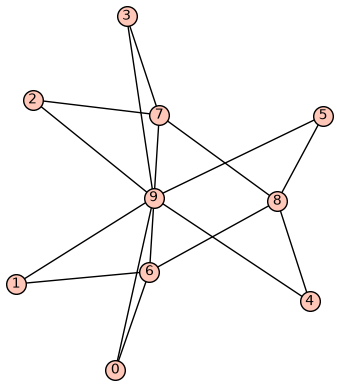

In [30]:
selected_class = 'b4'
selected_n = '10'
for code in five_color_graphs_all.get(selected_class, {}).get(selected_n, []):
    G = Graph(code, format='graph6')
    print(f'Razred {selected_class}, n={selected_n}, m={G.size()}')
    G.show()